# Phase IV results walkthrough

This notebook reads the files written by `scripts/evaluate.py` and shows where every number in the paper comes from. It doesn't recompute anything: to regenerate the files, run `python scripts/verify.py`. The outputs below come from a real kernel execution by `scripts/make_phase4_notebook.py`.

In [1]:
import csv, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES = ROOT / 'results' / 'phase4'
rows = list(csv.DictReader(open(RES / 'results.csv', encoding='utf-8')))
metrics = json.load(open(RES / 'metrics.json', encoding='utf-8'))
print(len(rows), 'rows in results.csv')

15 rows in results.csv


## Table 2: held-out results

Any-error labels for test (8 works) and extension (40 works), plus the identity-only rescoring (RQ3).

In [2]:
def fmt(v):
    return '-' if v in ('', None) else (f'{float(v):.3f}' if '.' in str(v) else v)

print(f"{'split':<11}{'method':<7}{'labels':<14}{'TP':>5}{'FP':>5}{'prec':>7}{'recall':>8}{'macro':>8}{'FPR':>7}")
for r in rows:
    print(f"{r['split']:<11}{r['method']:<7}{r['labels']:<14}{r['tp']:>5}{r['fp']:>5}{fmt(r['precision']):>7}{fmt(r['recall']):>8}{fmt(r['macro_recall']):>8}{fmt(r['fpr']):>7}")

split      method labels           TP   FP   prec  recall   macro    FPR
test       B1     any_error         8    0  1.000   0.200   0.200  0.000
test       B1     identity_only     8    0  1.000   0.333   0.333  0.000
test       B2     any_error        40    0  1.000   1.000   1.000  0.000
test       B2     identity_only    24   16  0.600   1.000   1.000  0.400
test       B3     any_error        40    0  1.000   1.000   1.000  0.000
test       B3     identity_only    24   16  0.600   1.000   1.000  0.400
ext        B1     any_error        40    0  1.000   0.200   0.200  0.000
ext        B1     identity_only    40    0  1.000   0.333   0.333  0.000
ext        B2     any_error       200    0  1.000   1.000   1.000  0.000
ext        B2     identity_only   120   80  0.600   1.000   1.000  0.400
ext        B3     any_error       200    0  1.000   1.000   1.000  0.000
ext        B3     identity_only   120   80  0.600   1.000   1.000  0.400
ext_stress B1     valid_only        0    0      -  

## Table 3: false flags on legitimate variants

Every one of these 87 citations is valid, so every flag is a false flag.

In [3]:
for m in ('B1', 'B2', 'B3'):
    per = metrics[f'ext_stress/{m}']['per_category']
    total = metrics[f'ext_stress/{m}']
    print(m, {c: f"{v['false_flags']}/{v['n']}" for c, v in per.items()}, '-> rate', round(total['false_flag_rate'], 3))

B1 {'et_al_first_author': '0/30', 'subtitle_dropped': '0/6', 'venue_abbrev': '0/11', 'print_year': '0/1', 'title_hyphen_break': '0/39'} -> rate 0.0
B2 {'et_al_first_author': '30/30', 'subtitle_dropped': '5/6', 'venue_abbrev': '11/11', 'print_year': '1/1', 'title_hyphen_break': '0/39'} -> rate 0.54
B3 {'et_al_first_author': '0/30', 'subtitle_dropped': '5/6', 'venue_abbrev': '11/11', 'print_year': '1/1', 'title_hyphen_break': '0/39'} -> rate 0.195


## Which field fired?

B2 records the failed field in `reason`, so each false flag can be traced to one rule.

In [4]:
from collections import Counter
preds = list(csv.DictReader(open(RES / 'predictions.csv', encoding='utf-8')))
fired = Counter((p['method'], p['category'], p['reason']) for p in preds if p['split'] == 'ext_stress' and p['decision'] == 'flag')
for (m, cat, reason), n in sorted(fired.items()):
    print(f'{m}  {cat:<20} {reason:<28} {n}')

B2  et_al_first_author   metadata_mismatch:authors    30
B2  print_year           metadata_mismatch:year       1
B2  subtitle_dropped     metadata_mismatch:title      5
B2  venue_abbrev         metadata_mismatch:venue      11
B3  print_year           metadata_mismatch:year       1
B3  subtitle_dropped     metadata_mismatch:title      5
B3  venue_abbrev         metadata_mismatch:venue      11


## One case end to end

The demo case: an "et al." citation that B2 flags and B3 passes.

In [5]:
case_id = 'extstress-000-et_al_first_author'
cases = {c['id']: c for c in json.load(open(ROOT / 'data' / 'ext_cases.json', encoding='utf-8'))}
print('cited authors:', cases[case_id]['citation']['authors'])
for p in preds:
    if p['id'] == case_id:
        print(p['method'], p['decision'], p['reason'])

cited authors: ['Spiegler']
B1 pass doi_registered
B2 flag metadata_mismatch:authors
B3 pass metadata_agrees


## Ablation and sensitivity

Descriptive only. The frozen thresholds were never changed.

In [6]:
for r in csv.DictReader(open(RES / 'ablation.csv', encoding='utf-8')):
    print(f"{r['variant']:<17} macro recall {float(r['macro_recall']):.2f}   false-flag rate {float(r['stress_false_flag_rate']):.3f}")
boot = json.load(open(RES / 'bootstrap.json', encoding='utf-8'))
print('\nB3-B2 stress false-flag difference, 95% interval:', boot['ext']['B3-B2_stress_flag_rate'])

B2 all fields     macro recall 1.00   false-flag rate 0.540
title only        macro recall 0.60   false-flag rate 0.057
authors only      macro recall 0.60   false-flag rate 0.345
year only         macro recall 0.60   false-flag rate 0.011
venue only        macro recall 0.40   false-flag rate 0.126
without title     macro recall 0.80   false-flag rate 0.483
without authors   macro recall 0.80   false-flag rate 0.195
without year      macro recall 0.80   false-flag rate 0.529
without venue     macro recall 1.00   false-flag rate 0.414

B3-B2 stress false-flag difference, 95% interval: {'lo': -0.39325842696629215, 'hi': -0.29347826086956524, 'n_valid': 2000}


## Figures

The same files used in the paper.

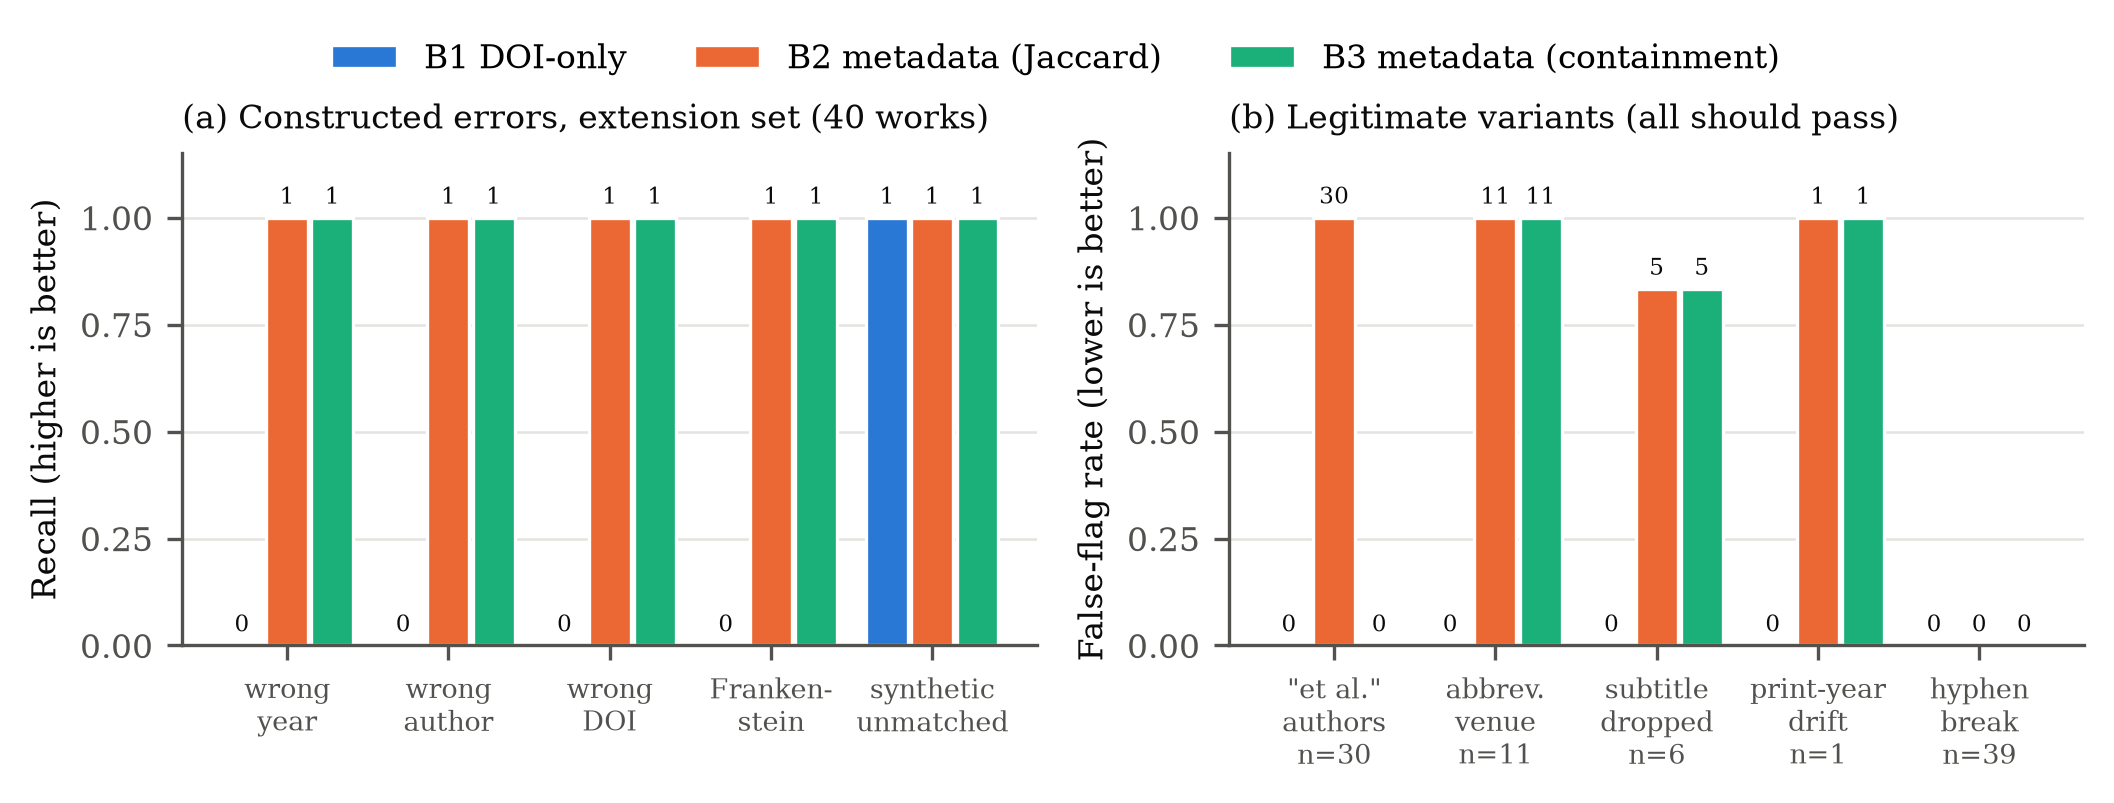

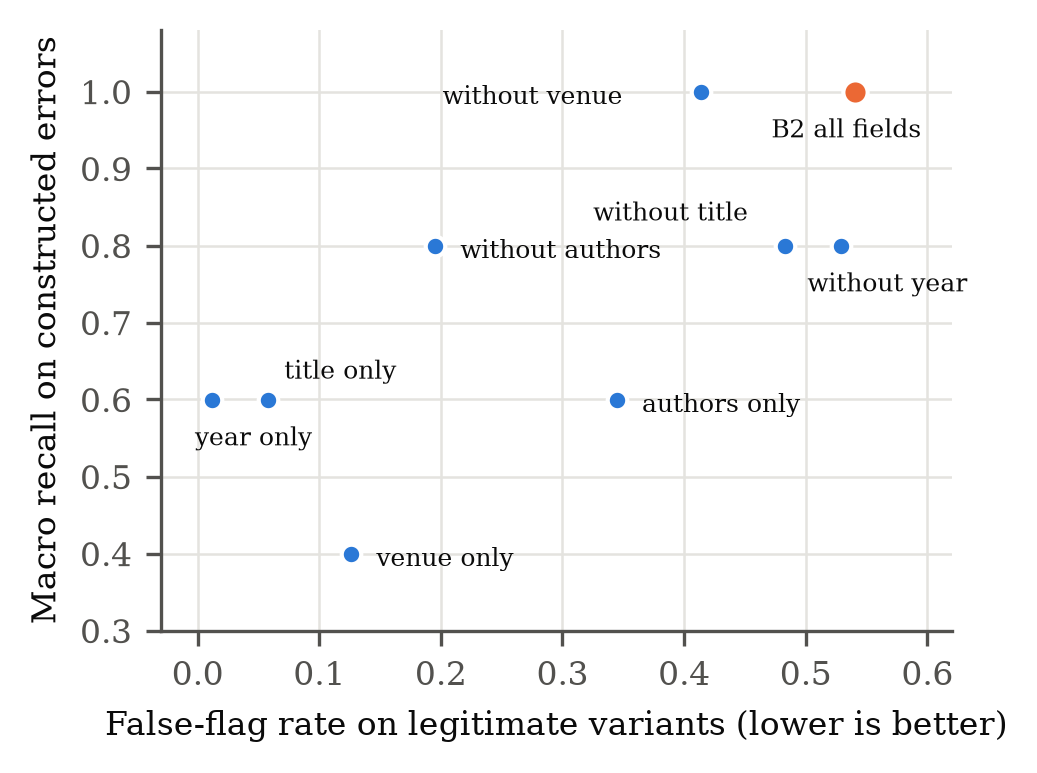

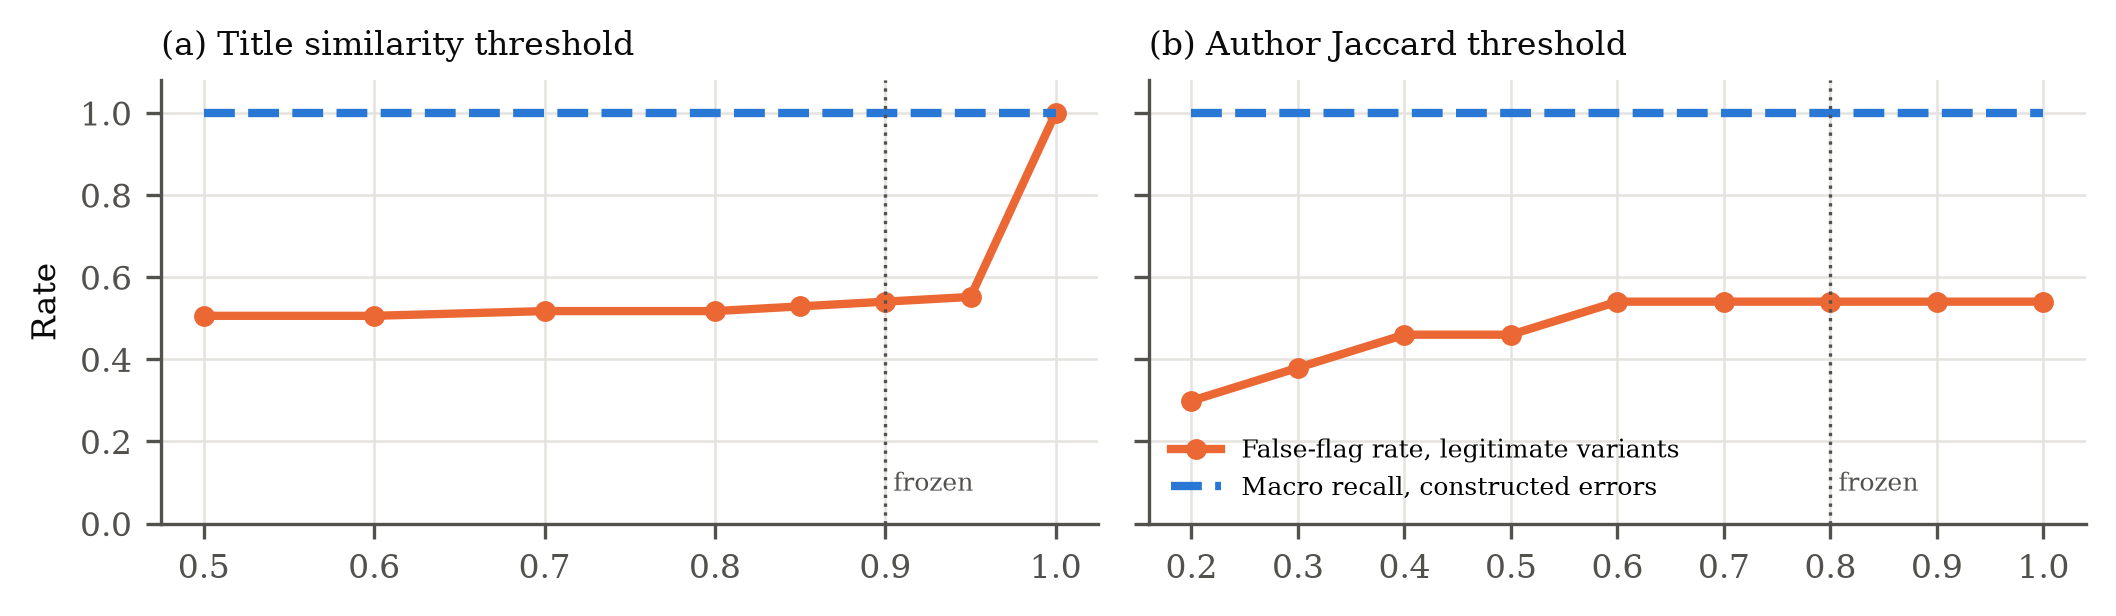

In [7]:
from IPython.display import Image, display
for name in ('fig_detection_false_flags', 'fig_ablation', 'fig_sensitivity'):
    display(Image(filename=str(ROOT / 'paper' / 'figures' / f'{name}.png'), width=700))

For interpretation and limitations see `../results_discussion.md` and Section 7 of the paper.